In [44]:
# !pip install open3d

In [37]:
#ВЫВЕСТИ 3Д МОДЕЛЬ В ОТДЕЛЬНОМ ОКНЕ
# import open3d as o3d
#
# # 1. Путь к твоему 3D-файлу (.obj, .ply, .stl, .gltf)
# mesh_path = "data_cache/obj_models/41b9b4576fd043b9bcda02fc9e9fd138.obj"  # Укажи путь к своей 3D-модели
#
# # 2. Загружаем TriangleMesh из файла
# mesh = o3d.io.read_triangle_mesh(mesh_path)
#
# # Проверяем, загрузилась ли модель
# if mesh.is_empty():
#     print("Ошибка: не удалось загрузить модель! Проверь путь к файлу.")
# else:
#     print(f"Модель успешно загружена!")
#     print(f"Количество вершин (vertices): {len(mesh.vertices)}")
#     print(f"Количество граней (triangles): {len(mesh.triangles)}")
#
# # 3. Расчёт нормалей (нужно, чтобы свет правильно отражался и объект выглядел объемным)
# mesh.compute_vertex_normals()
#
# # 4. Открываем окно визуализации
# o3d.visualization.draw_geometries(
#     [mesh],
#     window_name="Open3D - Просмотр 3D меша",
#     width=800,
#     height=600
# )


#ВЫВЕСТИ 3Д МОДЕЛЬ В ОТДЕЛЬНОМ ОКНЕ

In [38]:
from ObjaverseDataset import ObjaverseDataset
from torch.utils.data import DataLoader

In [39]:
dataset = ObjaverseDataset(uids=["41b9b4576fd043b9bcda02fc9e9fd138", "1f32bc0b4dd740f49faefc1cbe0e5e45"],category="Lego", start_index=1, limit=10)
dataloader = DataLoader(dataset, batch_size=1, shuffle=False, collate_fn=dataset.collate_fn)

In [40]:
#mesh = dataset[0]["mesh"]
mesh = dataset[1]["mesh"]

In [41]:
mesh.show()

In [42]:
# !pip install pyrender

May not work out of the box
Please use
`conda install -c conda-forge open3d`
or
`brew install libusb`

In [50]:
import os
import numpy as np
import open3d as o3d
import trimesh
def remove_platform_only(tmesh):
    """Удаляет ТОЛЬКО плоскую подставку, сохраняя голову, усы, глаза и тело."""
    # Если на входе сцена, собираем все меши
    if isinstance(tmesh, trimesh.Scene):
        geoms = [g for g in tmesh.geometry.values() if isinstance(g, trimesh.Trimesh)]
        if not geoms:
            return tmesh
        components = []
        for g in geoms:
            components.extend(g.split(only_watertight=False))
    elif isinstance(tmesh, trimesh.Trimesh):
        components = tmesh.split(only_watertight=False)
    else:
        return tmesh

    if len(components) <= 1:
        return tmesh

    cat_parts = []
    for comp in components:
        extents = comp.extents
        # Платформа характеризуется почти нулевой высотой по Y и малым числом полигонов
        is_platform = (extents[1] < 0.05 * max(extents[0], extents[2])) and (len(comp.faces) < 100)

        if not is_platform:
            cat_parts.append(comp)

    # Объединяем обратно все части кота с сохранением текстур/цветов
    if cat_parts:
        return trimesh.util.concatenate(cat_parts)
    return tmesh

def convert_trimesh_to_o3d(tmesh):
    """Convert Trimesh to Open3D TriangleMesh by preserving the colors"""

    tmesh = remove_platform_only(tmesh)


    o3d_mesh = o3d.geometry.TriangleMesh()
    o3d_mesh.vertices = o3d.utility.Vector3dVector(tmesh.vertices)
    o3d_mesh.triangles = o3d.utility.Vector3iVector(tmesh.faces)

    # Color transmition
    if hasattr(tmesh.visual, 'to_color'):
        color_visual = tmesh.visual.to_color()
        colors = color_visual.vertex_colors[:, :3] / 255.0
        o3d_mesh.vertex_colors = o3d.utility.Vector3dVector(colors)
    elif hasattr(tmesh.visual, 'vertex_colors') and tmesh.visual.vertex_colors is not None:
        colors = tmesh.visual.vertex_colors[:, :3] / 255.0
        o3d_mesh.vertex_colors = o3d.utility.Vector3dVector(colors)

    o3d_mesh.compute_vertex_normals()
    return o3d_mesh

def render_6_views(mesh_input, output_dir="rendered_views", width=800, height=800):
    """
    Генерирует 6 цветных картинок (спереди, сзади, слева, справа, сверху, снизу).
    Принимает путь к файлу (.obj) или объект trimesh / open3d.
    """
    os.makedirs(output_dir, exist_ok=True)

    # Приведение объекта к Open3D TriangleMesh
    if isinstance(mesh_input, str):
        mesh = o3d.io.read_triangle_mesh(mesh_input)
    elif isinstance(mesh_input, trimesh.Trimesh):
        mesh = convert_trimesh_to_o3d(mesh_input)
    elif isinstance(mesh_input, trimesh.Scene):
        tmesh = mesh_input.dump(concatenate=True)
        mesh = convert_trimesh_to_o3d(tmesh)
    else:
        mesh = mesh_input

    mesh.compute_vertex_normals()

    # Автоматический расчет центра и дистанции камеры
    bbox = mesh.get_axis_aligned_bounding_box()
    center = bbox.get_center()
    extent = bbox.get_max_extent()
    dist = extent * 2.2  # Отступ камеры

    # 6 ракурсов: (название, позиция камеры, вектор "верха")
    views = {
        "front":  (center + np.array([0, 0, dist]),   np.array([0, 1, 0])),
        "back":   (center + np.array([0, 0, -dist]),  np.array([0, 1, 0])),
        "left":   (center + np.array([-dist, 0, 0]),  np.array([0, 1, 0])),
        "right":  (center + np.array([dist, 0, 0]),   np.array([0, 1, 0])),
        "top":    (center + np.array([0, dist, 0]),   np.array([0, 0, -1])),
        "bottom": (center + np.array([0, -dist, 0]),  np.array([0, 0, 1]))
    }

    # Настройка автономного рендерера Open3D

    renderer = o3d.visualization.rendering.OffscreenRenderer(width, height)
    material = o3d.visualization.rendering.MaterialRecord()
    material.shader = "defaultLit"

    renderer.scene.add_geometry("mesh", mesh, material)
    renderer.scene.set_background(np.array([0.2, 0.2, 0.2, 1.0]))

    # --- НОВЫЙ КОД: Расчет границ для камеры без растяжений ---
    half_size = (extent / 2.0) * 1.2  # 1.2 дает 20% свободного места по краям
    aspect = width / height           # Учитываем пропорции картинки (чтобы не сплющило)

    for name, (eye, up) in views.items():
        # 1. Направляем камеру
        renderer.scene.camera.look_at(center, eye, up)

        # 2. Включаем ОРТОГРАФИЧЕСКУЮ проекцию (отключает перспективу и искажения)
        renderer.scene.camera.set_projection(
            o3d.visualization.rendering.Camera.Projection.Ortho,
            -half_size * aspect, half_size * aspect,  # left, right
            -half_size, half_size,                    # bottom, top
            0.1, dist * 5.0                           # near, far
        )

        # Рендерим и сохраняем
        img = renderer.render_to_image()
        file_path = os.path.join(output_dir, f"{name}.png")
        o3d.io.write_image(file_path, img)

    del renderer  # Освобождаем память

# Пример запуска с объектом из твоего датасета:
mesh = dataset[1]["mesh"]
render_6_views(mesh, output_dir=f"rendered_views/{dataset[1]['uid']}")

FEngine (64 bits) created at 0x1109dde00 (threading is enabled)
FEngine resolved backend: Metal
Selected physical device 'Apple M4'
Supported GPU families: 
  MTLGPUFamilyCommon3
  MTLGPUFamilyApple7
  MTLGPUFamilyMac2
Features:
  readWriteTextureSupport: true
Backend feature level: 3
FEngine feature level: 1


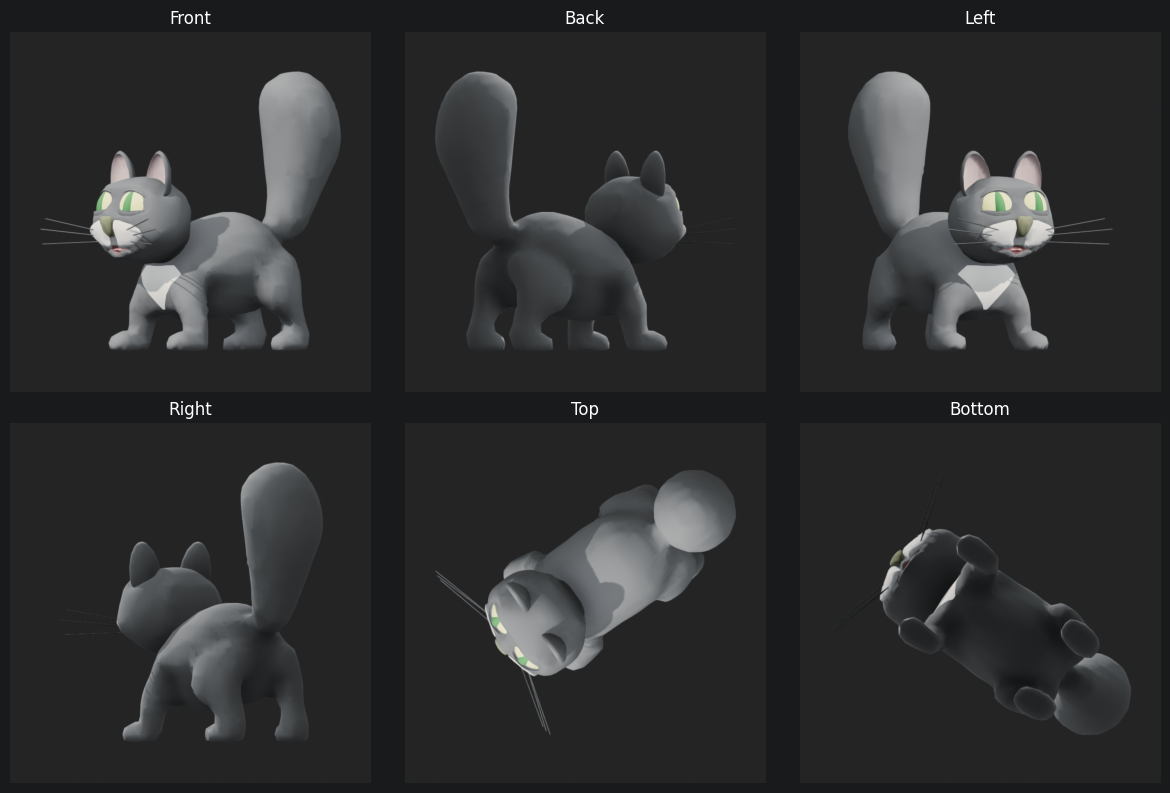

In [53]:
import os
import matplotlib.pyplot as plt
from PIL import Image

def show_rendered_grid(output_dir="rendered_views"):
    views = ["front", "back", "left", "right", "top", "bottom"]
    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    axes = axes.flatten()

    for i, view in enumerate(views):
        path = os.path.join(output_dir, f"{view}.png")
        if os.path.exists(path):
            img = Image.open(path)
            axes[i].imshow(img)
            axes[i].set_title(view.capitalize(), fontsize=12)
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()

# Отобразить картинки из папки
show_rendered_grid(f"rendered_views/{dataset[1]['uid']}")